# Genetic Painting
### Recreating a painting with 100 triangles

This notebook implements a Genetic Algorithm designed to recreate a target image using 100 triangles. By simulating natural selection, the algorithm iteratively refines color, position, and transparency to match the target across generations.

---

### Notebook structure

| Cell | Content |
|------|---------|
| 1 | Imports & environment setup |
| 2 | Configuration & target image |
| 3 | Render to image & RMSE fitness |
| 4 | GA operators - mutation, crossover, selection, fitness sharing, drawing order sort |
| 5 | Main GA loop  |
| 6 | Hyperparameter search space & tuning function |
| 7 | Run random search |
| 7b | Visualise tuning results |
| 8 | Final production run |
| 9 | Results - comparison and per-pixel error heatmap |
| 10 | Component ablation study - mutation, crossover and selection contribution |

## 1. Imports & environment setup

In [15]:
import time, itertools, random, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from numba import njit, prange
from PIL import Image

## 2. Configuration & target image

Here we define the genome size and load the image. 

The DNA of each individual is a flat float32 array. With 100 triangles and 10 parameters per triangle (x1, y1, x2, y2, x3, y3, r, g, b, a).

In [ ]:
TARGET_WIDTH       = 300
TARGET_HEIGHT      = 400
NUM_TRIANGLES      = 100
GENES_PER_TRIANGLE = 10  # (x1,y1), (x2,y2), (x3,y3) , r,g,b, a 
DNA_LENGTH         = NUM_TRIANGLES * GENES_PER_TRIANGLE

# Target image
TARGET_PATH = "data/target.png"  # 300 x 400 image

def load_and_prep_target(image_path):
    img = (
        Image.open(image_path)
        .convert("RGB")
    )
    return np.array(img, dtype=np.float32)

target_image = load_and_prep_target(TARGET_PATH)
print("Target image loaded")

Target image loaded


## 3. Render to image & RMSE fitness

The renderer reshapes this DNA into a list of triangles. Each triangle contains:
- 3 vertex positions (x1, y1, x2, y2, x3, y3)
- RGB colour values
- Alpha (transparency)

Each triangle is drawn by only looping over its bounding box instead of scanning the whole image, which keeps things efficient.

The triangle’s colour is then blended into the image using alpha blending, meaning it mixes with whatever is already underneath based on its transparency.

Fitness is measured using RMSE (Root Mean Squared Error), which simply compares each pixel in the generated image to the target image. Lower values mean the image is closer to the target.

In [ ]:
@njit(fastmath=True)
def render_dna_to_image(dna, width, height):
    """
    Renders a flattened DNA vector into an RGB image using triangle rasterisation.

    Each DNA vector encodes a fixed number of triangles. Each triangle contains:
        - 3 vertex positions (x1, y1, x2, y2, x3, y3) in normalised [0, 1] space
        - RGB colour values (r, g, b)
        - Alpha transparency (a)

    The function:
        1. Reshapes the DNA into a triangle array
        2. Scales vertex positions to image coordinates
        3. Rasterises each triangle using barycentric coordinate tests
        4. Applies alpha blending to accumulate colour contributions

    Parameters
    ----------
    dna : np.ndarray
        Flat float32 array representing all triangles in the image.
        Shape: (NUM_TRIANGLES * GENES_PER_TRIANGLE,)

    width : int
        Width of the output image in pixels.

    height : int
        Height of the output image in pixels.

    Returns
    -------
    np.ndarray
        Rendered image of shape (height, width, 3) with float32 RGB values.
    """
    img       = np.full((height, width, 3), dtype=np.float32)
    triangles = dna.reshape((NUM_TRIANGLES, GENES_PER_TRIANGLE))

    for i in range(NUM_TRIANGLES):
        tri = triangles[i]
        x1, y1 = int(tri[0] * width),  int(tri[1] * height)
        x2, y2 = int(tri[2] * width),  int(tri[3] * height)
        x3, y3 = int(tri[4] * width),  int(tri[5] * height)

        r, g, b = tri[6] * 255.0, tri[7] * 255.0, tri[8] * 255.0
        a = tri[9]

        minX = max(0, min(x1, x2, x3));  maxX = min(width  - 1, max(x1, x2, x3))
        minY = max(0, min(y1, y2, y3));  maxY = min(height - 1, max(y1, y2, y3))

        vs1x, vs1y = x2 - x1, y2 - y1
        vs2x, vs2y = x3 - x1, y3 - y1
        den = vs1x * vs2y - vs2x * vs1y
        if den == 0: continue

        for py in range(minY, maxY + 1):
            for px in range(minX, maxX + 1):
                qx, qy = px - x1, py - y1
                s = (qx * vs2y - qy * vs2x) / den
                t = (vs1x * qy - vs1y * qx) / den
                if s >= 0 and t >= 0 and s + t <= 1:
                    img[py, px, 0] = r * a + img[py, px, 0] * (1.0 - a)
                    img[py, px, 1] = g * a + img[py, px, 1] * (1.0 - a)
                    img[py, px, 2] = b * a + img[py, px, 2] * (1.0 - a)
    return img


@njit(parallel=True, fastmath=True)
def evaluate_population_numba(population, target, width, height):
    """
    Evaluates a population of DNA individuals by rendering each one into an image
    and computing its fitness using RMSE against the target image.

    The evaluation is parallelised across CPU cores using Numba's prange for speed.

    Parameters
    ----------
    population : np.ndarray
        Array of shape (pop_size, DNA_LENGTH) representing all individuals.

    target : np.ndarray
        Target image to compare against, shape (height, width, 3).

    width : int
        Width of the rendered image.

    height : int
        Height of the rendered image.

    Returns
    -------
    np.ndarray
        Array of shape (pop_size,) containing RMSE fitness values
        (lower values indicate better similarity to the target).
    """
    pop_size  = population.shape[0]
    fitnesses = np.zeros(pop_size, dtype=np.float32)
    for i in prange(pop_size):
        img = render_dna_to_image(population[i], width, height)
        diff = target - img
        fitnesses[i] = np.sqrt(np.mean(diff * diff))
    return fitnesses


## 4. GA operators

### Mutation: six triangle-level operators

Instead of bitwise mutations, which would change meaningless parts of a number, mutations act on whole triangles. There are six operators:

| # | Mutation Type | Probability | What it does |
|---|---|---|---|
| 1 | Vertex jitter | 30% | Slightly moves one corner of the triangle |
| 2 | Translation | 20% | Shifts the whole triangle to a new position |
| 3 | Rotation | 20% | Rotates the triangle around its centre |
| 4 | Edge stretch | 15% | Pulls one corner closer to or further from the centre |
| 5 | Coherent colour shift | 10% | Adjusts brightness and slightly changes colour temperature |
| 6 | Alpha shift | 5% | Makes the triangle more or less transparent |

Mutation strength scales with triangle area and decays over generations.

### Crossover
- Uniform (0): each triangle is independently inherited from either parent with a 50/50 chance  
- Single-point (1): a random cut-point splits the triangle list between the two parents

### Selection
- Tournament (0): randomly chosen individuals compete, and the fittest is selected  
- Rank roulette (1): individuals are selected probabilistically based on fitness ranking

### Fitness sharing
Individuals that are too similar to others in the population get penalised. If many solutions cluster in the same region of the search space, their effective fitness is reduced. This encourages the population to spread out and explore multiple promising areas instead of converging to a single solution too early.

### Drawing order sort
Triangles inside each individual are sorted by size (area), so larger shapes are drawn first and smaller details are layered on top. This helps the image build up more naturally, with broad background regions laid down before fine details.

In [ ]:
# Helper functions

@njit(fastmath=True)
def _clamp01(x): 
    """
    Clamps a scalar value to the range [0, 1].

    Ensures that inputs stay within valid bounds for normalized
    coordinates, color channels, and alpha values.

    Parameters
    ----------
    x : float
        Input value to be clamped.

    Returns
    -------
    float
        Value clipped to the range [0, 1].
    """
    if x < 0.0: return 0.0
    if x > 1.0: return 1.0
    return x

@njit(fastmath=True)
def _triangle_area(x1, y1, x2, y2, x3, y3):
    """
    Computes the (scaled) area of a triangle using the cross-product method.

    The result is proportional to the true geometric area and is used
    for relative comparisons (e.g., adaptive mutation strength), not
    absolute measurement.

    Parameters
    ----------
    x1, y1 : float
        Coordinates of the first vertex.
    x2, y2 : float
        Coordinates of the second vertex.
    x3, y3 : float
        Coordinates of the third vertex.

    Returns
    -------
    float
        Absolute value of twice the triangle area.
    """
    return abs((x2 - x1) * (y3 - y1) - (x3 - x1) * (y2 - y1))


# Mutation 

@njit(fastmath=True)
def triangle_mutation(dna, mutation_prob, mutation_strength):
    """
    Applies semantic mutation to a single individual by modifying one or more
    randomly selected triangles in its DNA representation.

    The mutation operates at the triangle level and chooses between several
    geometric and visual perturbations:
        - Vertex jitter (moving a single vertex)
        - Translation (moving the whole triangle)
        - Rotation around centroid
        - Radial edge stretch/shrink relative to centroid
        - Colour adjustment (brightness + warm/cool shift)
        - Alpha (transparency) adjustment

    The magnitude of mutation is adaptive and depends on triangle size:
    larger triangles (by area) receive stronger perturbations.

    Parameters
    ----------
    dna : np.ndarray
        Flat float32 array encoding all triangles in the individual.

    mutation_prob : float
        Probability that this individual will undergo mutation.

    mutation_strength : float
        Base strength controlling the scale of all perturbations.

    Returns
    -------
    np.ndarray
        Mutated copy of the input DNA (or unchanged copy if not selected).
    """
    child = np.copy(dna)
    if np.random.rand() > mutation_prob:
        return child

    num_mut = np.random.randint(1, 4)
    for _ in range(num_mut):
        tri_idx = np.random.randint(0, NUM_TRIANGLES)
        base = tri_idx * GENES_PER_TRIANGLE

        x1 = child[base]; y1 = child[base + 1]
        x2 = child[base + 2]; y2 = child[base + 3]
        x3 = child[base + 4]; y3 = child[base + 5]

        area = _triangle_area(x1, y1, x2, y2, x3, y3)
        local_str = mutation_strength * (0.25 + area * 2.0)   # larger triangle means bigger nudge

        mt = np.random.rand()
        # 1. Vertex jitter
        if mt < 0.3:        
            randomx = np.random.randint(0, 3)
            px = base + randomx * 2; py = px + 1
            child[px] = _clamp01(child[px] + np.random.normal(0, local_str))
            child[py] = _clamp01(child[py] + np.random.normal(0, local_str))
        # 2. Translation
        elif mt < 0.5:      
            dx = np.random.normal(0, local_str)
            dy = np.random.normal(0, local_str)
            for randomx in range(3):
                px = base + randomx * 2; py = px + 1
                child[px] = _clamp01(child[px] + dx)
                child[py] = _clamp01(child[py] + dy)
        # 3. Rotation around centroid
        elif mt < 0.7:      
            cx = (x1 + x2 + x3) / 3.0; cy = (y1 + y2 + y3) / 3.0
            theta = np.random.normal(0, local_str * 5.0)
            ct = np.cos(theta); st = np.sin(theta)
            for xcoord in range(3):
                pxi = base + xcoord * 2; pyi = pxi + 1
                dx = child[pxi] - cx; dy = child[pyi] - cy
                child[pxi] = _clamp01(cx + dx * ct - dy * st)
                child[pyi] = _clamp01(cy + dx * st + dy * ct)
        # 4. Edge stretch
        elif mt < 0.85:      
            randomx = np.random.randint(0, 3)
            px = base + randomx * 2; py = px + 1
            cx = (x1 + x2 + x3) / 3.0; cy = (y1 + y2 + y3) / 3.0
            dx = child[px] - cx; dy = child[py] - cy
            stretch = 1.0 + np.random.normal(0, local_str * 3.0)
            child[px] = _clamp01(cx + dx * stretch)
            child[py] = _clamp01(cy + dy * stretch)
        # 5. Colour shift (brightness + warm/cool)
        elif mt < 0.95:      
            brightness = np.random.normal(0, local_str)
            for c in range(3):
                child[base + 6 + c] = _clamp01(child[base + 6 + c] + brightness)
            temp = np.random.normal(0, local_str * 0.5)
            child[base + 6] = _clamp01(child[base + 6] + temp)   # + = red
            child[base + 8] = _clamp01(child[base + 8] - temp)   # - = blue
        # 6. Alpha shift
        else:       
            child[base + 9] = _clamp01(
                child[base + 9] + np.random.normal(0, local_str * 0.5)
            )

    return child


# Drawing order sort 

def sort_triangles_by_area(population):
    """
    Reorders triangles inside each individual so that larger triangles are
    placed before smaller ones in the DNA sequence.

    This ensures correct painter-style rendering order, where large
    background shapes are drawn first and smaller detail triangles are
    layered on top.

    The sorting is based on triangle area computed via the cross-product
    formula applied to each triangle's vertex coordinates.

    Parameters
    ----------
    population : np.ndarray
        Array of shape (pop_size, DNA_LENGTH), where each individual is
        a flattened sequence of triangle genes.

    Returns
    -------
    np.ndarray
        New population array with triangles internally sorted by descending
        area for each individual.
    """
    sorted_pop = np.empty_like(population)
    for i in range(population.shape[0]):
        triangles  = population[i].reshape((NUM_TRIANGLES, GENES_PER_TRIANGLE))
        areas = np.abs(
            (triangles[:, 2] - triangles[:, 0]) * (triangles[:, 5] - triangles[:, 1]) -
            (triangles[:, 4] - triangles[:, 0]) * (triangles[:, 3] - triangles[:, 1])
        )
        order = np.argsort(areas)[::-1]   # descending so largest first
        sorted_pop[i] = triangles[order].reshape(DNA_LENGTH)
    return sorted_pop


# Crossover

@njit(fastmath=True)
def crossover(parent1, parent2, crossover_type):
    """
    Performs genetic crossover between two parent individuals to produce two offspring.

    Two crossover strategies are supported:

    - Uniform crossover (crossover_type = 0):
      Each triangle (gene block) is independently swapped between parents
      with 50% probability.

    - Single-point crossover (crossover_type = 1):
      A single cut point is chosen across the flattened DNA sequence,
      and all genes before and after the cut are exchanged between parents.

    This maintains triangle-level structure by operating on full gene blocks
    rather than individual floats.

    Parameters
    ----------
    parent1 : np.ndarray
        First parent DNA vector.

    parent2 : np.ndarray
        Second parent DNA vector.

    crossover_type : int
        0 for uniform crossover, 1 for single-point crossover.

    Returns
    -------
    tuple of np.ndarray
        Two offspring (child1, child2) produced from the parents.
    """
    child1 = np.empty(DNA_LENGTH, dtype=np.float32)
    child2 = np.empty(DNA_LENGTH, dtype=np.float32)

    if crossover_type == 0:
        for i in range(NUM_TRIANGLES):
            s = i * GENES_PER_TRIANGLE; e = s + GENES_PER_TRIANGLE
            if np.random.rand() > 0.5:
                child1[s:e] = parent1[s:e]; child2[s:e] = parent2[s:e]
            else:
                child1[s:e] = parent2[s:e]; child2[s:e] = parent1[s:e]
    else:
        cut = np.random.randint(1, NUM_TRIANGLES) * GENES_PER_TRIANGLE
        child1[:cut]  = parent1[:cut];  child1[cut:] = parent2[cut:]
        child2[:cut]  = parent2[:cut];  child2[cut:] = parent1[cut:]

    return child1, child2


# Selection

@njit(fastmath=True)
def get_elites_and_parents(population, fitnesses, pop_size, elitism_count, tournament_k, selection_type):
    """
    Performs elitism selection and generates a parent pool for reproduction.

    The function preserves the best-performing individuals (elitism) and
    selects the remaining parents using one of two selection strategies:

    1. Tournament selection (selection_type = 0):
       Random subsets of individuals compete, and the fittest in each
       tournament is selected. The tournament size is controlled by
       `tournament_k`.

    2. Rank-based roulette selection (selection_type = 1):
       Individuals are selected probabilistically based on their rank
       in the sorted population, giving higher-ranked individuals
       a higher chance of being chosen.

    The output includes:
        - A new population array with elites copied directly
        - A separate parent pool used for crossover

    Parameters
    ----------
    population : np.ndarray
        Current population of individuals.

    fitnesses : np.ndarray
        Fitness values for each individual (lower is better).

    pop_size : int
        Total number of individuals in the population.

    elitism_count : int
        Number of top individuals preserved unchanged.

    tournament_k : int
        Number of competitors in each tournament (only used in tournament mode).

    selection_type : int
        0 = Tournament selection
        1 = Rank-based roulette selection

    Returns
    -------
    tuple
        new_population : np.ndarray
            Population array with elites copied into it.

        parents : np.ndarray
            Selected parent pool for generating offspring.
    """
    new_population = np.empty_like(population)
    sorted_indices = np.argsort(fitnesses)

    for i in range(elitism_count):
        new_population[i] = population[sorted_indices[i]]

    num_parents = pop_size - elitism_count
    parents = np.empty((num_parents, DNA_LENGTH), dtype=np.float32)

    # Tournament
    if selection_type == 0:        
        for i in range(num_parents):
            best_idx = np.random.randint(0, pop_size)
            best_fit = fitnesses[best_idx]
            for _ in range(1, tournament_k):
                idx = np.random.randint(0, pop_size)
                if fitnesses[idx] < best_fit:
                    best_fit = fitnesses[idx]; best_idx = idx
            parents[i] = population[best_idx]

    # Rank roulette
    else:        
        rank_sum = pop_size * (pop_size + 1) / 2.0
        for i in range(num_parents):
            pick = np.random.rand() * rank_sum
            current = 0.0
            selected = sorted_indices[-1]
            for j in range(pop_size):
                current += (pop_size - j)
                if current >= pick:
                    selected = sorted_indices[j]; break
            parents[i] = population[selected]

    return new_population, parents


# Fitness sharing  

@njit(parallel=True, fastmath=True)
def apply_fitness_sharing(fitnesses, population, sigma_share):
    """
    Applies fitness sharing to preserve diversity in the population by
    penalising individuals located in densely populated regions of the
    search space.

    For each individual, a "niche count" is computed based on how many
    other individuals lie within a given distance threshold in DNA space.
    Individuals in crowded regions receive a higher penalty, reducing their
    effective fitness advantage.

    The sharing function is defined as:
        sh(d) = 1 - (d / sigma_share), if d < sigma_share, else 0

    This encourages exploration of multiple peaks in the fitness landscape
    instead of premature convergence to a single solution.

    Parameters
    ----------
    fitnesses : np.ndarray
        Array of raw fitness values (lower is better).

    population : np.ndarray
        Population of DNA individuals.

    sigma_share : float
        Radius of the sharing neighbourhood. Smaller values enforce
        weaker diversity pressure; larger values increase it.

    Returns
    -------
    np.ndarray
        Fitness values adjusted by diversity pressure (shared fitness).
    """
    pop_size = population.shape[0]
    shared_fitnesses = np.copy(fitnesses)

    for i in prange(pop_size):
        niche_count = 0.0
        for j in range(pop_size):
            # Normalised Euclidean distance in DNA space
            d = np.sqrt(np.mean((population[i] - population[j]) ** 2))
            if d < sigma_share:
                niche_count += 1.0 - (d / sigma_share)
        if niche_count > 1.0:
            shared_fitnesses[i] = fitnesses[i] * niche_count

    return shared_fitnesses

## 5. Main GA loop
The run_genetic_algorithm function handles the generational lifecycle.

### Key design decisions

| Feature | Implementation |
|---------|---------------|
| Soft alpha init | Alpha genes are scaled by 0.1 at initialization, making triangles nearly transparent at the start |
| Adaptive mutation decay | mutation_strength decreases linearly over generations but is clamped to a minimum value of 0.01 |
| Fitness sharing | Applied before selection when sigma_share > 0, encouraging population diversity |
| Drawing order sort | Every sort_interval generations, triangles are sorted by area (largest first) within each individual |
| Softer stagnation reset | Worst 20% of individuals are replaced with heavily mutated copies of the best DNA, preserving learned structure while injecting diversity |

In [ ]:
def run_genetic_algorithm(
    target,
    pop_size = 200,
    generations = 5000,
    mutation_prob = 0.45,
    base_mutation_strength = 0.06,
    crossover_rate = 0.90,
    tournament_k = 7,
    elitism_count = 2,
    crossover_type = 0,          # 0=Uniform  1=Single-Point
    selection_type = 0,          # 0=Tournament  1=Rank
    stagnation_limit = 200,
    sigma_share = 0.25,          # sharing radius (0 = disabled)
    sort_interval = 100,         # sort triangles by area every N gens (0 = disabled)
    verbose = True,
):
    """
    Runs a triangle-based genetic algorithm to approximate a target image.

    The algorithm evolves a population of individuals where each individual
    encodes an image as a set of triangles. Over time, the population is
    optimised using selection, crossover, mutation, and optional diversity
    preservation mechanisms.

    Key components:
        - Elitism: preserves best-performing individuals each generation
        - Selection: tournament or rank-based roulette selection
        - Crossover: uniform or single-point recombination of triangles
        - Mutation: geometric + colour perturbations per triangle
        - Fitness: RMSE between rendered image and target image
        - Fitness sharing: optional diversity preservation in DNA space
        - Stagnation recovery: injects mutated copies of best solution
        - Triangle sorting: ensures painter-style rendering order

    Parameters
    ----------
    target : np.ndarray
        Target image to approximate.

    pop_size : int
        Number of individuals in the population.

    generations : int
        Number of evolutionary iterations.

    mutation_prob : float
        Probability that an individual undergoes mutation.

    base_mutation_strength : float
        Base scale of mutation noise.

    crossover_rate : float
        Probability of applying crossover between parents.

    tournament_k : int
        Number of competitors in tournament selection.

    elitism_count : int
        Number of top individuals preserved each generation.

    crossover_type : int
        0 = Uniform crossover
        1 = Single-point crossover

    selection_type : int
        0 = Tournament selection
        1 = Rank-based roulette selection

    stagnation_limit : int
        Number of generations without improvement before triggering recovery.

    sigma_share : float
        Radius for fitness sharing (0 disables diversity pressure).

    sort_interval : int
        Interval (in generations) for sorting triangles by area.

    verbose : bool
        If True, prints training progress.

    Returns
    -------
    tuple
        best_dna : np.ndarray
            Best solution found (flattened DNA vector)

        best_rmse : list[float]
            Best RMSE value per generation
    """

    # Initialise 
    population = np.random.rand(pop_size, DNA_LENGTH).astype(np.float32)
    for i in range(pop_size):
        for t in range(NUM_TRIANGLES):
            population[i, t * GENES_PER_TRIANGLE + 9] *= 0.1   # softens the alphas

    best_rmse = []
    best_overall_dna  = None
    best_overall_rmse = float("inf")
    stagnation_counter= 0
    start_time = time.time()

    for gen in range(generations):

        # Adaptive mutation strength
        decay = 1.0 - gen / generations
        mutation_strength = max(0.01, base_mutation_strength * decay)

        # Evaluate 
        raw_fitnesses = evaluate_population_numba(population, target, TARGET_WIDTH, TARGET_HEIGHT)

        # Fitness sharing (diversity pressure) 
        if sigma_share > 0:
            selection_fitnesses = apply_fitness_sharing(raw_fitnesses, population, sigma_share)
        else:
            selection_fitnesses = raw_fitnesses

        # Track best
        min_idx = np.argmin(raw_fitnesses)
        current_best_rmse = float(raw_fitnesses[min_idx])
        best_rmse.append(current_best_rmse)


        if current_best_rmse < best_overall_rmse - 0.001:
            best_overall_rmse = current_best_rmse
            best_overall_dna = np.copy(population[min_idx])
            stagnation_counter = 0
        else:
            stagnation_counter += 1

        # Selection
        new_pop, parents = get_elites_and_parents(population, selection_fitnesses, pop_size, elitism_count, tournament_k, selection_type)
        num_parents = len(parents)

        # Crossover + Mutation   
        for i in range(elitism_count, pop_size, 2):
            if i + 1 >= pop_size: break
            p1 = parents[np.random.randint(num_parents)]
            p2 = parents[np.random.randint(num_parents)]
            if np.random.rand() < crossover_rate:
                c1, c2 = crossover(p1, p2, crossover_type)
            else:
                c1, c2 = np.copy(p1), np.copy(p2)
            new_pop[i] = triangle_mutation(c1, mutation_prob, mutation_strength)
            new_pop[i + 1] = triangle_mutation(c2, mutation_prob, mutation_strength)

        population = new_pop

        # Drawing order sort       
        if sort_interval > 0 and gen > 0 and gen % sort_interval == 0:
            population = sort_triangles_by_area(population)

        # Stagnation reset         
        # Replace worst 20% with mutated copies of the best individual.
        # This preserves the learned colour and shape structure while injecting
        # enough variation to escape the local optimum, unlike a full random
        # reset that ignores everything the GA has learned.
        if stagnation_counter >= stagnation_limit:
            num_replace   = int(0.2 * pop_size)
            worst_indices = np.argsort(raw_fitnesses)[-num_replace:]

            for idx in worst_indices:
                disturbed = np.copy(best_overall_dna)
                # Apply stronger mutation to create diversity
                for _ in range(8):
                    disturbed = triangle_mutation(
                        disturbed,
                        mutation_prob = 1.0, # always mutate
                        mutation_strength= base_mutation_strength * 2.5 # 2.5× normal
                    )
                population[idx] = disturbed

            stagnation_counter = 0
            if verbose:
                print(
                    f"  Gen {gen:5d} | Reseted - {num_replace} individuals "
                    f"replaced with perturbed-best  (RMSE={current_best_rmse:.4f})"
                )

        # Logging
        if verbose and (gen % 100 == 0 or gen == generations - 1):
            elapsed = time.time() - start_time
            print(
                f"  Gen {gen:5d} | "
                f"RMSE: {current_best_rmse:.4f} | "
                f"MutStr: {mutation_strength:.5f} | "
                f"Stag: {stagnation_counter:4d} | "
                f"Time: {elapsed:.1f}s"
            )

    return best_overall_dna, best_rmse

## 6. Hyperparameter search space & tuning function

To extract the best possible performance, we use a Random Search strategy to explore different configurations of the GA parameters.

### Key design choices

| Feature | Implementation |
|---------|---------------|
| Search strategy | Random sampling from a full Cartesian product of parameter combinations |
| Evaluation metric | Final RMSE from the last generation of each run |
| Stochastic robustness | Each configuration is evaluated over multiple independent runs (runs_per_trial) |
| Rank-selection cleanup | When using rank-based selection, tournament_k is neutralized to a fixed value to avoid redundant configurations |
| Result aggregation | Final score is averaged across runs, with standard deviation reported for stability |

### Notes

- Each trial is independent and uses full GA runs
- Only the final generation RMSE is used for ranking configurations

In [ ]:
CROSSOVER_LABELS = {0: "Uniform", 1: "Single-Point"}
SELECTION_LABELS = {0: "Tournament", 1: "Rank"}
FIXED_TOURNAMENT_K = 5   # used for rank-selection trials so we don't waste a trial on tournament_k
param_space = {
    # population
    "pop_size": [100],

    # mutation
    # 0.10 = fine exploitation, 0.25 = aggressive exploration
    "mutation_prob": [0.4, 0.5, 0.6],
    "base_mutation_strength": [0.10, 0.15, 0.20, 0.25],

    # crossover  
    "crossover_rate": [0.70, 0.90],
    "crossover_type": [0, 1], # 0 = Uniform, 1 = Single-Point

    # selection  
    "selection_type": [0, 1], # 0 = Tournament, 1 = Rank
    "tournament_k": [3, 5], # tournament_k is only meaningful when selection_type == 0

    # elitism 
    "elitism_count": [3, 5, 7],

    # stagnation 
    "stagnation_limit": [150, 200],

    # fitness sharing radius
    "sigma_share": [0.0, 0.1, 0.2],   # 0.0 = disabled
}


def tune_ga(
    target,
    search_generations = 500,
    n_trials = 15,
    runs_per_trial = 3,
):
    """
    Performs random search hyperparameter tuning for the genetic algorithm.

    Each sampled hyperparameter configuration is evaluated multiple times
    to reduce stochastic noise. Performance is measured using the final
    RMSE of the GA run (lower is better).

    The function also handles invalid parameter redundancy cases:
    when rank-based selection is used, tournament_k is irrelevant and is
    normalised to a fixed value to avoid duplicate configurations.

    Parameters
    ----------
    target : np.ndarray
        Target image used for fitness evaluation.

    search_generations : int
        Number of generations used for each evaluation run during tuning.

    n_trials : int
        Number of hyperparameter configurations to sample and evaluate.

    runs_per_trial : int
        Number of independent runs per configuration (for averaging stability).

    Returns
    -------
    pd.DataFrame
        Sorted table of configurations ranked by average final RMSE.
        Includes mean and standard deviation across runs.
    """
    print(
        f"Random search: {n_trials} trials × {runs_per_trial} runs "
        f"× {search_generations} generations  |  metric = Final RMSE"
    )
    print("=" * 72)

    keys, values = zip(*param_space.items())
    all_combos   = [dict(zip(keys, v)) for v in itertools.product(*values)]

    #    tournament_k guard        
    # Configs that differ only in tournament_k while using rank
    # selection are equivalent - collapse them to avoid redundant trials.
    seen_signatures = set()
    unique_combos   = []
    for cfg in all_combos:
        if cfg["selection_type"] == 1:
            cfg = dict(cfg)
            cfg["tournament_k"] = FIXED_TOURNAMENT_K   # normalise
        sig = tuple(sorted(cfg.items()))
        if sig not in seen_signatures:
            seen_signatures.add(sig)
            unique_combos.append(cfg)

    sampled = random.sample(unique_combos, min(n_trials, len(unique_combos)))

    results = []
    for trial_i, params in enumerate(sampled, start=1):
        sel_label = SELECTION_LABELS[params["selection_type"]]
        co_label  = CROSSOVER_LABELS[params["crossover_type"]]
        tk_display = params["tournament_k"] if params["selection_type"] == 0 else "N/A"

        print(
            f"\nTrial {trial_i:2d}/{n_trials} | "
            f"pop={params['pop_size']} | "
            f"mut_p={params['mutation_prob']} | "
            f"mut_s={params['base_mutation_strength']} | "
            f"crossover={co_label} | sel={sel_label} | "
            f"k={tk_display} | elite={params['elitism_count']} | "
            f"stag={params['stagnation_limit']} | "
            f"sigma={params['sigma_share']}"
        )

        trial_final_rmses  = []

        for run in range(runs_per_trial):
            _, history = run_genetic_algorithm(
                target = target,
                generations = search_generations,
                verbose = False,
                sort_interval = 50,   # keep drawing order sort on during search
                **params,
            )
            final_rmse = history[-1]
            trial_final_rmses.append(final_rmse)
            print(
                f"    Run {run+1}/{runs_per_trial} | "
                f"final RMSE: {final_rmse:.4f}"
            )

        avg_final_rmse = float(np.mean(trial_final_rmses))
        std_final_rmse = float(np.std(trial_final_rmses))
        print(f"   Trial avg Final RMSE: {avg_final_rmse:.4f}  (±{std_final_rmse:.4f})")

        record = {
            "trial": trial_i,
            "avg_final_rmse": avg_final_rmse,
            "std_final_rmse": std_final_rmse,
            "tk_effective": tk_display,
            **params,
        }
        results.append(record)

    df = pd.DataFrame(results).sort_values("avg_final_rmse").reset_index(drop=True)
    return df


## 7. Run random search

The tuner is executed and the best-performing configuration is extracted based on average final RMSE.
It runs 15 trials with 500 generations and 3 runs each.

### Steps:
1. Run hyperparameter search using multiple GA evaluations per configuration
2. Sort configurations by avg_final_rmse
3. Extract the best-performing parameter set
4. Clean up and format parameters for reuse in the main GA
5. Print a readable summary of the best configuration

In [ ]:
tuning_results = tune_ga(
    target = target_image,
    search_generations = 500,  
    n_trials = 15,   # configs to sample
    runs_per_trial = 3,     
)

# Extract best config
best_row = tuning_results.iloc[0].to_dict()
best_params = {
    k: v for k, v in best_row.items()
    if k not in ("trial", "avg_final_rmse", "std_final_rmse", "tk_effective")
}
for int_key in ("pop_size", "tournament_k", "elitism_count", "stagnation_limit", "crossover_type", "selection_type"):
    best_params[int_key] = int(best_params[int_key])

print("\nBest configuration:")
for k, v in best_params.items():
    extra = ""
    if k == "crossover_type": extra = f"  ({CROSSOVER_LABELS[int(v)]})"
    if k == "selection_type":  extra = f"  ({SELECTION_LABELS[int(v)]})"
    print(f"  {k:24s}: {v}{extra}")

Random search: 15 trials × 3 runs × 500 generations  |  metric = Final RMSE

Trial  1/15 | pop=100 | mut_p=0.5 | mut_s=0.2 | crossover=Uniform | sel=Tournament | k=5 | elite=3 | stag=200 | sigma=0.1
    Run 1/3 | final RMSE: 34.4565
    Run 2/3 | final RMSE: 33.0127
    Run 3/3 | final RMSE: 34.4366
   Trial avg Final RMSE: 33.9686  (±0.6760)

Trial  2/15 | pop=100 | mut_p=0.4 | mut_s=0.15 | crossover=Single-Point | sel=Tournament | k=5 | elite=5 | stag=150 | sigma=0.2
    Run 1/3 | final RMSE: 34.4932
    Run 2/3 | final RMSE: 33.6161
    Run 3/3 | final RMSE: 35.8110
   Trial avg Final RMSE: 34.6401  (±0.9021)

Trial  3/15 | pop=100 | mut_p=0.5 | mut_s=0.25 | crossover=Uniform | sel=Tournament | k=5 | elite=7 | stag=150 | sigma=0.0
    Run 1/3 | final RMSE: 29.3889
    Run 2/3 | final RMSE: 28.7729
    Run 3/3 | final RMSE: 29.9539
   Trial avg Final RMSE: 29.3719  (±0.4823)

Trial  4/15 | pop=100 | mut_p=0.4 | mut_s=0.2 | crossover=Single-Point | sel=Rank | k=N/A | elite=7 | stag=15

### 7b. Visualise tuning results

This dashboard visualizes how different hyperparameters influenced the final RMSE, highlighting interactions between exploration (mutation) and exploitation (elitism/crossover) in our trials.

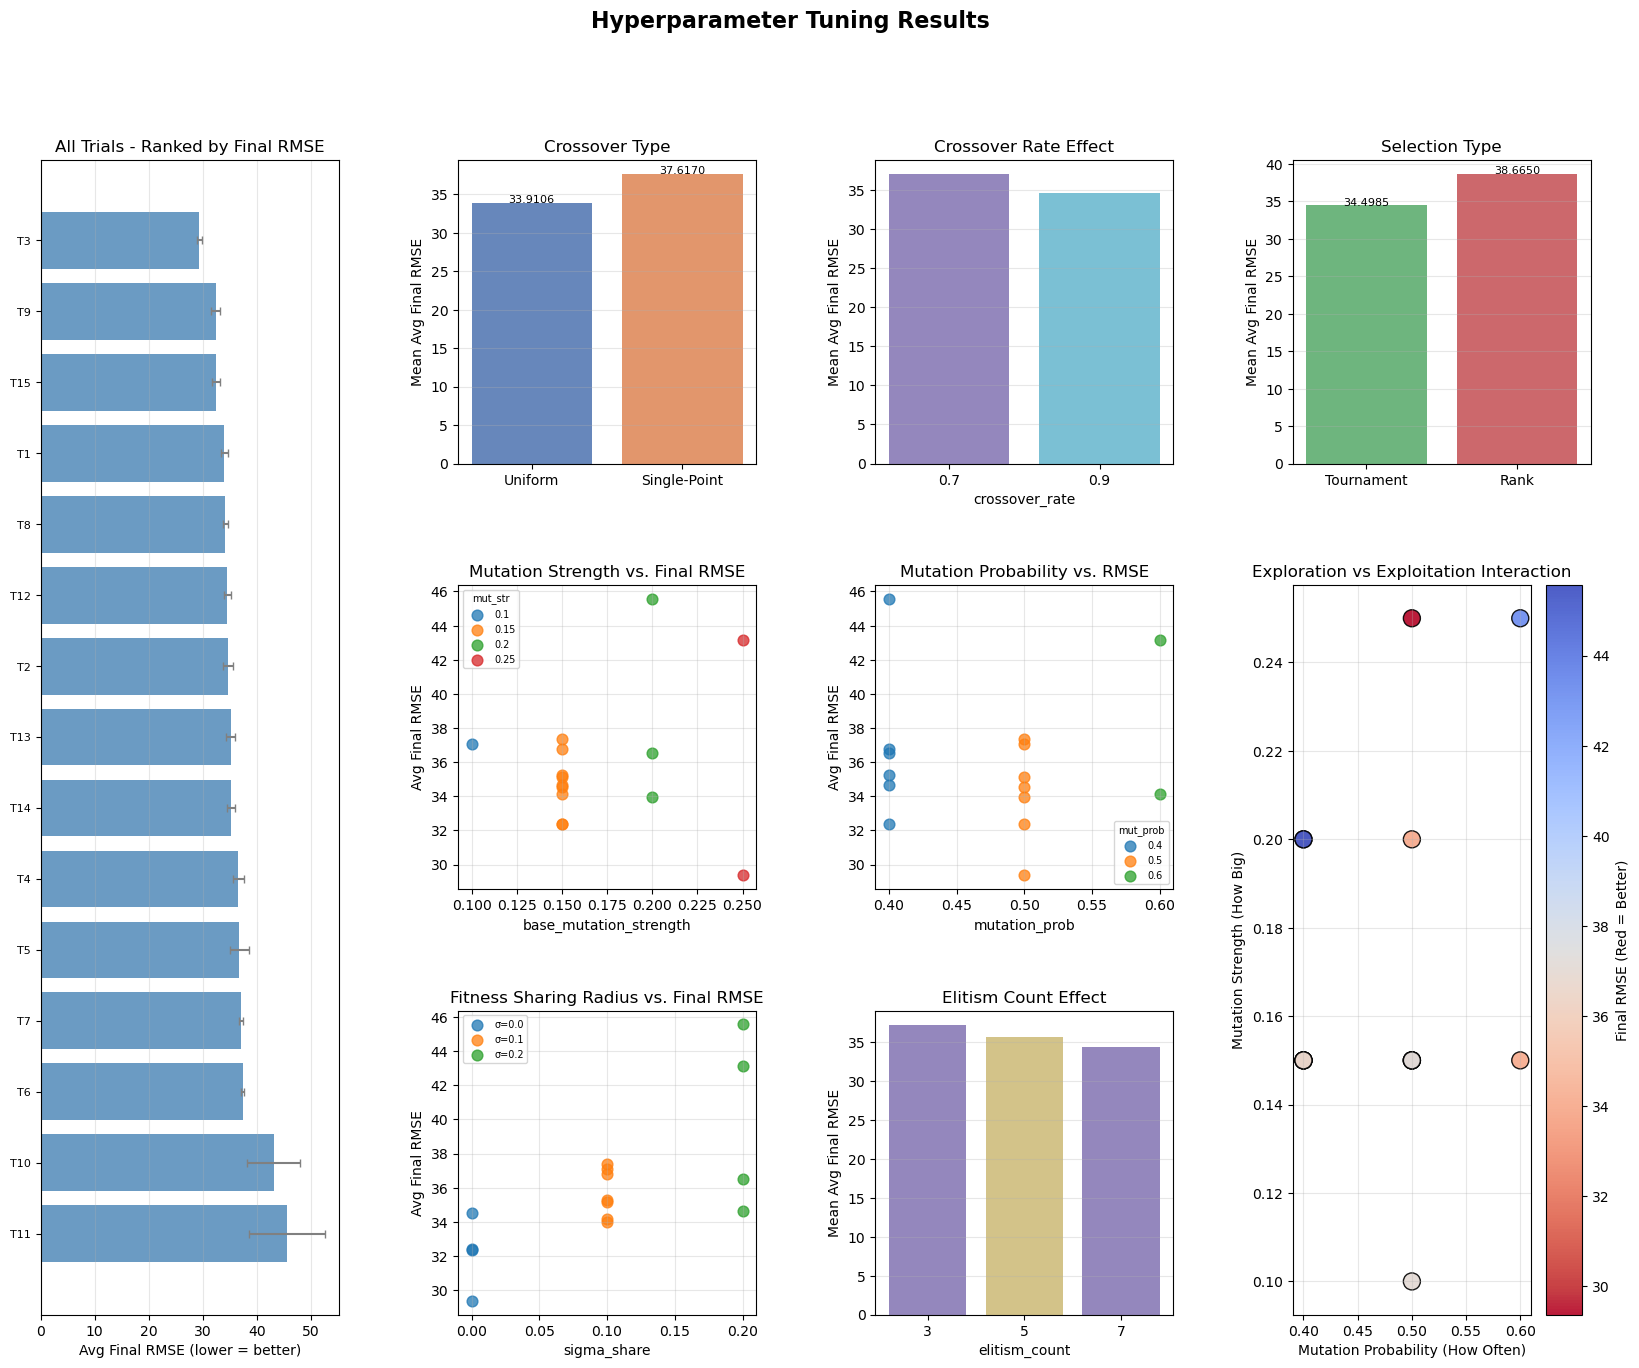

In [22]:
fig = plt.figure(figsize=(20, 15)) 
gs  = GridSpec(3, 4, figure=fig, hspace=0.4, wspace=0.4)

ax0 = fig.add_subplot(gs[:, 0])
ax0.barh(
    range(len(tuning_results)), tuning_results["avg_final_rmse"],
    xerr=tuning_results["std_final_rmse"],
    color="steelblue", alpha=0.8, ecolor="grey", capsize=3
)
# Trials
ax0.set_yticks(range(len(tuning_results)))
ax0.set_yticklabels([f"T{int(r['trial'])}" for _, r in tuning_results.iterrows()], fontsize=8)
ax0.set_xlabel("Avg Final RMSE (lower = better)")
ax0.set_title("All Trials - Ranked by Final RMSE")
ax0.invert_yaxis()
ax0.grid(axis="x", alpha=0.3)

# Crossover
ax1 = fig.add_subplot(gs[0, 1])
co_means = tuning_results.groupby("crossover_type")["avg_final_rmse"].mean()
ax1.bar([CROSSOVER_LABELS[int(k)] for k in co_means.index],
        co_means.values, color=["#4C72B0", "#DD8452"], alpha=0.85)
ax1.set_ylabel("Mean Avg Final RMSE");  ax1.set_title("Crossover Type")
ax1.grid(axis="y", alpha=0.3)
for bar, val in zip(ax1.patches, co_means.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
             f"{val:.4f}", ha="center", fontsize=8)

# Crossover rate
ax3 = fig.add_subplot(gs[0, 2])
cr_means = tuning_results.groupby("crossover_rate")["avg_final_rmse"].mean()
ax3.bar([str(k) for k in cr_means.index], cr_means.values,
        color=["#8172B2", "#64B5CD"], alpha=0.85)
ax3.set_xlabel("crossover_rate");  ax3.set_ylabel("Mean Avg Final RMSE")
ax3.set_title("Crossover Rate Effect");  ax3.grid(axis="y", alpha=0.3)

# Selection
ax2 = fig.add_subplot(gs[0, 3])
sel_means = tuning_results.groupby("selection_type")["avg_final_rmse"].mean()
ax2.bar([SELECTION_LABELS[int(k)] for k in sel_means.index],
        sel_means.values, color=["#55A868", "#C44E52"], alpha=0.85)
ax2.set_ylabel("Mean Avg Final RMSE");  ax2.set_title("Selection Type")
ax2.grid(axis="y", alpha=0.3)
for bar, val in zip(ax2.patches, sel_means.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
             f"{val:.4f}", ha="center", fontsize=8)

# Mutation Strength
ax4 = fig.add_subplot(gs[1, 1])
for mut_str, grp in tuning_results.groupby("base_mutation_strength"):
    ax4.scatter([mut_str] * len(grp), grp["avg_final_rmse"],
                label=f"{mut_str}", s=60, alpha=0.75)
ax4.set_xlabel("base_mutation_strength");  ax4.set_ylabel("Avg Final RMSE")
ax4.set_title("Mutation Strength vs. Final RMSE")
ax4.legend(title="mut_str", fontsize=7, title_fontsize=7)
ax4.grid(alpha=0.3)

# Mutation Probability
ax5 = fig.add_subplot(gs[1, 2])
for mut_p, grp in tuning_results.groupby("mutation_prob"):
    ax5.scatter([mut_p] * len(grp), grp["avg_final_rmse"],
                label=f"{mut_p}", s=60, alpha=0.75)
ax5.set_xlabel("mutation_prob");  ax5.set_ylabel("Avg Final RMSE")
ax5.set_title("Mutation Probability vs. RMSE")
ax5.legend(title="mut_prob", fontsize=7, title_fontsize=7)
ax5.grid(alpha=0.3)

# Fitness Share
ax6 = fig.add_subplot(gs[2, 1])
for sig, grp in tuning_results.groupby("sigma_share"):
    ax6.scatter([sig] * len(grp), grp["avg_final_rmse"],
                label=f"σ={sig}", s=60, alpha=0.75)
ax6.set_xlabel("sigma_share");  ax6.set_ylabel("Avg Final RMSE")
ax6.set_title("Fitness Sharing Radius vs. Final RMSE")
ax6.legend(fontsize=7);  ax6.grid(alpha=0.3)

# Elitism
ax7 = fig.add_subplot(gs[2, 2])
el_means = tuning_results.groupby("elitism_count")["avg_final_rmse"].mean()
ax7.bar([str(int(k)) for k in el_means.index], el_means.values,
        color=["#8172B2", "#CCB974"], alpha=0.85)
ax7.set_xlabel("elitism_count");  ax7.set_ylabel("Mean Avg Final RMSE")
ax7.set_title("Elitism Count Effect");  ax7.grid(axis="y", alpha=0.3)

# Scatter plot
ax8 = fig.add_subplot(gs[1:, 3])
sc2 = ax8.scatter(
    tuning_results["mutation_prob"], tuning_results["base_mutation_strength"],
    c=tuning_results["avg_final_rmse"], cmap="coolwarm_r", s=150, alpha=0.9, edgecolors="black"
)
plt.colorbar(sc2, ax=ax8, label="Final RMSE (Red = Better)")
ax8.set_xlabel("Mutation Probability (How Often)");  
ax8.set_ylabel("Mutation Strength (How Big)")
ax8.set_title("Exploration vs Exploitation Interaction")
ax8.grid(alpha=0.3)

plt.suptitle("Hyperparameter Tuning Results",
             fontsize=16, fontweight="bold")
plt.show()

## 8. Final Run

The best hyperparameter configuration found during the random search is used for a long final optimisation.

This run is intended to produce the highest-quality image approximation by allowing the genetic algorithm sufficient generations to fully converge.

### Key details:
- Population size is raised to 200 for better performance
- The algorithm runs for 10000 generations
- Sorting of triangles is applied every 100 generations to stabilise rendering order
- All best-found hyperparameters from tuning are reused directly

The final RMSE reported corresponds to the last generation of the run.

In [29]:
FINAL_GENERATIONS = 10000 
best_params["pop_size"] = 200
print(f"Starting final run with {FINAL_GENERATIONS} generations")
print("Config:")
for k, v in best_params.items():
    extra = ""
    if k == "crossover_type": extra = f"  ({CROSSOVER_LABELS[int(v)]})"
    if k == "selection_type":  extra = f"  ({SELECTION_LABELS[int(v)]})"
    if k == "tournament_k" and best_params["selection_type"] == 1:
        extra = "  (N/A - rank selection active)"
    print(f"  {k:20s}: {v}{extra}")
print()

best_dna, fitness_history = run_genetic_algorithm(
    target = target_image,
    generations = FINAL_GENERATIONS,
    sort_interval = 100,
    verbose = True,
    **best_params,
)

print(f"\nFinal RMSE: {fitness_history[-1]:.4f}")


Starting final run with 10000 generations
Config:
  pop_size            : 200
  mutation_prob       : 0.5
  base_mutation_strength: 0.25
  crossover_rate      : 0.7
  crossover_type      : 0  (Uniform)
  selection_type      : 0  (Tournament)
  tournament_k        : 5
  elitism_count       : 7
  stagnation_limit    : 150
  sigma_share         : 0.0

  Gen     0 | RMSE: 74.4618 | MutStr: 0.25000 | Stag:    0 | Time: 0.1s
  Gen   100 | RMSE: 38.6704 | MutStr: 0.24750 | Stag:    0 | Time: 17.3s
  Gen   200 | RMSE: 32.8740 | MutStr: 0.24500 | Stag:    0 | Time: 33.2s
  Gen   300 | RMSE: 29.6918 | MutStr: 0.24250 | Stag:    0 | Time: 49.0s
  Gen   400 | RMSE: 27.2247 | MutStr: 0.24000 | Stag:    0 | Time: 63.7s
  Gen   500 | RMSE: 25.9009 | MutStr: 0.23750 | Stag:    1 | Time: 78.8s
  Gen   600 | RMSE: 24.8755 | MutStr: 0.23500 | Stag:    0 | Time: 93.4s
  Gen   700 | RMSE: 24.0796 | MutStr: 0.23250 | Stag:    0 | Time: 108.0s
  Gen   800 | RMSE: 23.3964 | MutStr: 0.23000 | Stag:    0 | Time

## 9. Results & diagnostics

This cell visualises the final output of the genetic algorithm and provides diagnostics for convergence and reconstruction quality.

### Panels:
1. Target image – ground truth painting  
2. GA result – best evolved approximation with final RMSE displayed  
3. RMSE convergence curve – best fitness per generation over time  
4. Per-pixel error heatmap – mean absolute error per pixel, highlighting regions where the GA struggled most  


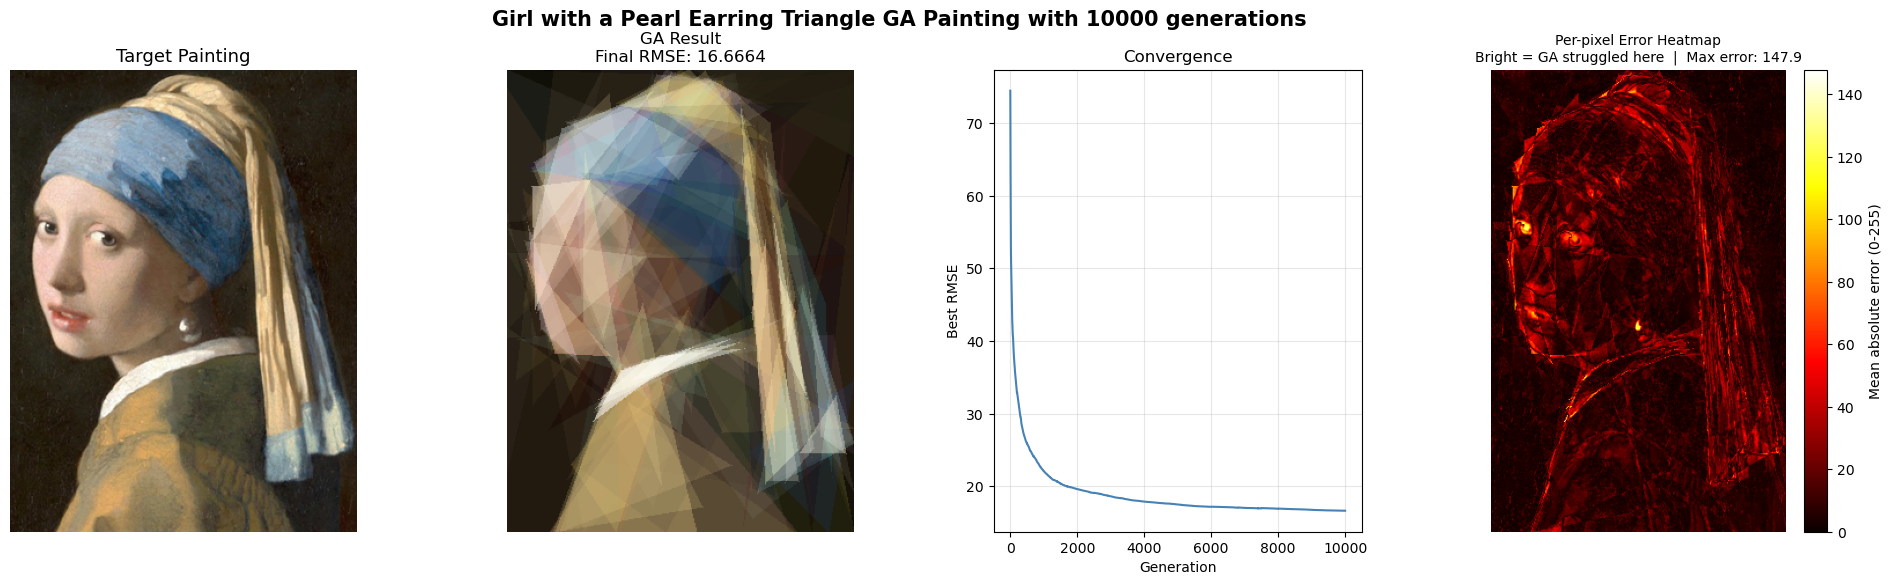

Final Result
  RMSE: 16.6664

Result saved to 'CIFO_final_triangle_ga_result.png'


In [ ]:
final_image = render_dna_to_image(best_dna, TARGET_WIDTH, TARGET_HEIGHT)
final_image_u8 = np.clip(final_image, 0, 255).astype(np.uint8)

# Per-pixel error map (mean absolute error across RGB channels)
error_map = np.abs(target_image - final_image) 
error_magnitude = error_map.mean(axis=2)

# Panel layout
fig = plt.figure(figsize=(24, 6))
gs  = GridSpec(1, 4, figure=fig, hspace=0.35, wspace=0.35)

# Target
ax_target = fig.add_subplot(gs[:, 0])
ax_target.imshow(target_image.astype(np.uint8))
ax_target.set_title("Target Painting", fontsize=13)
ax_target.axis("off")

# GA result                  
ax_result = fig.add_subplot(gs[:, 1])
ax_result.imshow(final_image_u8)
ax_result.set_title(
    f"GA Result\n"
    f"Final RMSE: {fitness_history[-1]:.4f}",
    fontsize=12
)
ax_result.axis("off")

# RMSE convergence 
ax_conv = fig.add_subplot(gs[:, 2])
ax_conv.plot(fitness_history, linewidth=1.5, color="steelblue")
ax_conv.set_xlabel("Generation");  ax_conv.set_ylabel("Best RMSE")
ax_conv.set_title("Convergence")
ax_conv.grid(True, alpha=0.3)


# Per-pixel error heatmap
ax_heat = fig.add_subplot(gs[:, 3])
im = ax_heat.imshow(error_magnitude, cmap="hot", aspect="auto",
                    vmin=0, vmax=error_magnitude.max())
plt.colorbar(im, ax=ax_heat, label="Mean absolute error (0-255)")
ax_heat.set_title(
    f"Per-pixel Error Heatmap\n"
    f"Bright = GA struggled here  |  Max error: {error_magnitude.max():.1f}",
    fontsize=10
)
ax_heat.axis("off")

plt.suptitle(
    f"Girl with a Pearl Earring Triangle GA Painting with {FINAL_GENERATIONS} generations",
    fontsize=15, fontweight="bold"
)
plt.show()

# Summary statistics            
print("Final Result")
print(f"  RMSE: {fitness_history[-1]:.4f}")

# Save result                   
out_path = "CIFO_final_triangle_ga_result.png"
Image.fromarray(final_image_u8).save(out_path)
print(f"\nResult saved to '{out_path}'")

## 10. Component Ablation Study

This study evaluates the contribution of key genetic algorithm components: mutation, crossover, and selection.

### Method

Starting from the best configuration found during hyperparameter tuning (best_params), one component is modified or disabled at a time while keeping all other parameters fixed.

| Condition | Modification | Purpose |
|-----------|-------------|--------|
| Full GA | No changes | Baseline performance |
| No mutation | mutation_prob = 0.0 | Tests whether mutation is required for improvement |
| No crossover | crossover_rate = 0.0 | Measures contribution of recombination |
| Random selection | Uses tournament selection with k = 1 (equivalent to uniform random selection) | Removes selection pressure |

### Notes
- selection_type = 2 is a synthetic flag used only for ablation and is internally mapped to tournament selection with k = 1
- Each condition is evaluated over multiple independent runs
- Performance is measured using final RMSE and convergence behaviour over generations

In [31]:
# Ablation study settings
ABLATION_GENERATIONS = 500   # kept short so the study runs in a reasonable time
ABLATION_RUNS = 3

# Build the four conditions from best_params
ablation_conditions = {
    "Full GA": dict(best_params),
    "No Mutation": dict(best_params, mutation_prob=0.0),
    "No Crossover": dict(best_params, crossover_rate=0.0),
    "Random Selection": dict(best_params, selection_type=2),
}


# We do not want to change the run_genetic_algorithm, so instead we patch the
# selection call only for the Random Selection condition.

def run_ablation_condition(condition_name, params, target, generations, runs):
    """
    Runs `runs` independent GA trials for one ablation condition.
    Returns a list of per-run convergence histories.
    """
    histories = []
    run_params = dict(params)

    # To achieve Random Selection we use tournament with k=1 (picks a winner uniformly at random)
    # k=1 tournament equals uniform random selection so no fitness pressure at all.
    if run_params.get("selection_type") == 2:
        run_params["selection_type"] = 0   # tournament
        run_params["tournament_k"]   = 1   # k=1 random winner

    for run_idx in range(runs):
        print(f"  [{condition_name}] run {run_idx + 1}/{runs} ...", end=" ", flush=True)
        _, history = run_genetic_algorithm(
            target      = target,
            generations = generations,
            sort_interval = 50,
            verbose     = False,
            **run_params,
        )
        histories.append(history)
        print(f"final RMSE = {history[-1]:.4f}")

    return histories


# Run all conditions 
print(f"Ablation study: {len(ablation_conditions)} conditions × "
      f"{ABLATION_RUNS} runs × {ABLATION_GENERATIONS} generations")
print("=" * 60)

ablation_results = {}   # condition_name -> list of histories
for cond_name, cond_params in ablation_conditions.items():
    print(f"\nCondition: {cond_name}")
    ablation_results[cond_name] = run_ablation_condition(
        cond_name, cond_params, target_image, ABLATION_GENERATIONS, ABLATION_RUNS
    )

Ablation study: 4 conditions × 3 runs × 500 generations

Condition: Full GA
  [Full GA] run 1/3 ... final RMSE = 27.8849
  [Full GA] run 2/3 ... final RMSE = 28.2078
  [Full GA] run 3/3 ... final RMSE = 27.6051

Condition: No Mutation
  [No Mutation] run 1/3 ... final RMSE = 46.1205
  [No Mutation] run 2/3 ... final RMSE = 45.7505
  [No Mutation] run 3/3 ... final RMSE = 45.9261

Condition: No Crossover
  [No Crossover] run 1/3 ... final RMSE = 35.0098
  [No Crossover] run 2/3 ... final RMSE = 36.0152
  [No Crossover] run 3/3 ... final RMSE = 33.5234

Condition: Random Selection
  [Random Selection] run 1/3 ... final RMSE = 48.0108
  [Random Selection] run 2/3 ... final RMSE = 44.5887
  [Random Selection] run 3/3 ... final RMSE = 46.9891



---------------------------------------------------------------
Condition                Avg Final RMSE    ± Std   vs Full GA
---------------------------------------------------------------
Full GA                         27.8993   0.2462      +0.0000
No Mutation                     45.9324   0.1511     +18.0331
No Crossover                    34.8495   1.0236      +6.9502
Random Selection                46.5295   1.4344     +18.6302


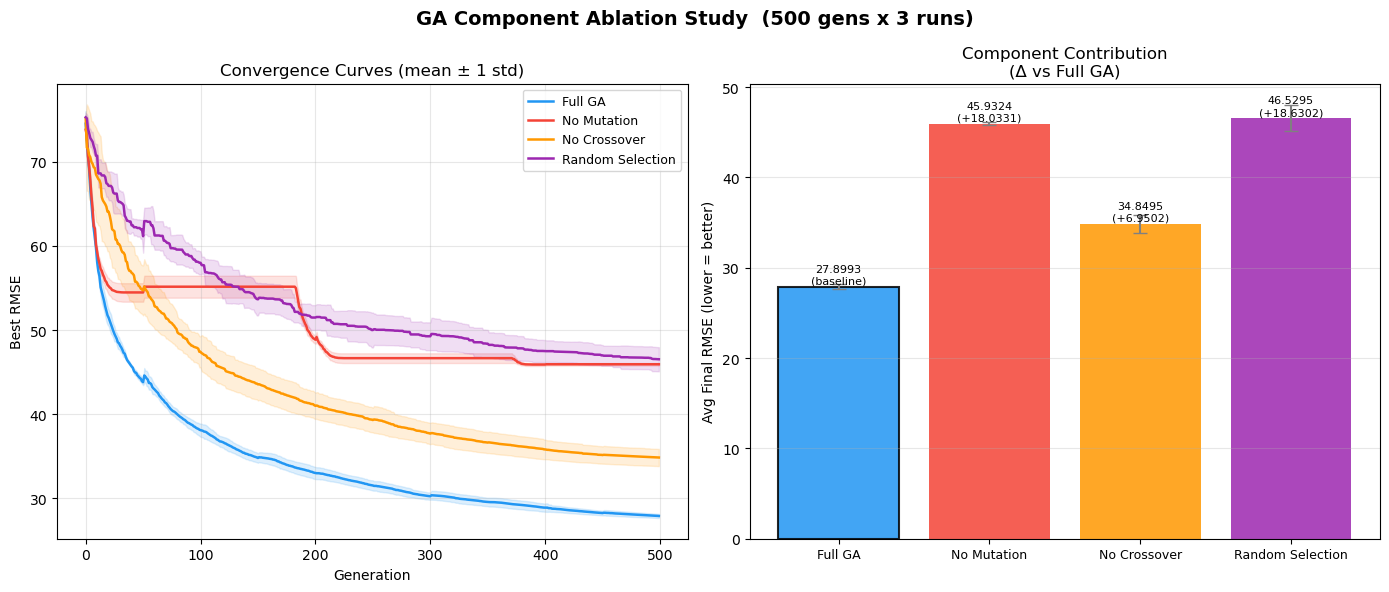


Interpretation guide
  Mutation contributes a lot to the final result  (without it the RMSE gets worse by +18.0331 RMSE)
  Crossover contributes significantly to the final result  (without it the RMSE gets worse by +6.9502 RMSE)
  Selection contributes a lot to the final result  (without it the RMSE gets worse by +18.6302 RMSE)


In [ ]:
# Summary table 
print("\n" + "-" * 63)
print(f"{'Condition':<22} {'Avg Final RMSE':>16} {'± Std':>8} {'vs Full GA':>12}")
print("-" * 63)

summary = {}
for cond_name, histories in ablation_results.items():
    finals = np.array([h[-1] for h in histories])
    summary[cond_name] = {"mean": finals.mean(), "std": finals.std(), "histories": histories}

baseline = summary["Full GA"]["mean"]
for cond_name, stats in summary.items():
    delta = stats["mean"] - baseline
    delta_str = f"+{delta:.4f}" if delta >= 0 else f"{delta:.4f}"
    print(f"{cond_name:<22} {stats['mean']:>16.4f} {stats['std']:>8.4f} {delta_str:>12}")


# Visualisation 
COLORS = {
    "Full GA":          "#2196F3",
    "No Mutation":      "#F44336",
    "No Crossover":     "#FF9800",
    "Random Selection": "#9C27B0",
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Convergence curves
ax = axes[0]
for cond_name, stats in summary.items():
    histories  = np.array(stats["histories"]) 
    mean_curve = histories.mean(axis=0)
    std_curve  = histories.std(axis=0)
    gens = np.arange(len(mean_curve))
    ax.plot(gens, mean_curve, label=cond_name, color=COLORS[cond_name], linewidth=1.8)
    ax.fill_between(gens,
                    mean_curve - std_curve,
                    mean_curve + std_curve,
                    color=COLORS[cond_name], alpha=0.15)
ax.set_xlabel("Generation")
ax.set_ylabel("Best RMSE")
ax.set_title("Convergence Curves (mean ± 1 std)")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

# Final RMSE bar chart with error bars (Shifted to axes[1])
ax = axes[1]
cond_names = list(summary.keys())
means = [summary[c]["mean"] for c in cond_names]
stds  = [summary[c]["std"]  for c in cond_names]
colors = [COLORS[c] for c in cond_names]

bars = ax.bar(cond_names, means, yerr=stds, color=colors, alpha=0.85,
              ecolor="grey", capsize=5)
# Annotate each bar
for bar, mean_val, cond_name in zip(bars, means, cond_names):
    delta = mean_val - baseline
    sign  = "+" if delta >= 0 else ""
    label = f"{mean_val:.4f}\n({sign}{delta:.4f})" if cond_name != "Full GA" else f"{mean_val:.4f}\n(baseline)"
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(stds) * 0.1,
            label, ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Avg Final RMSE (lower = better)")
ax.set_title("Component Contribution\n(Δ vs Full GA)")
ax.set_xticks(range(len(cond_names)))
ax.set_xticklabels(cond_names, fontsize=9)
ax.grid(axis="y", alpha=0.3)
# Highlight the baseline bar
bars[0].set_edgecolor("black")
bars[0].set_linewidth(1.5)

plt.suptitle(
    f"GA Component Ablation Study  ({ABLATION_GENERATIONS} gens x {ABLATION_RUNS} runs)",
    fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()


# Interpretation 
print("\nInterpretation guide")
for cond_name in ["No Mutation", "No Crossover", "Random Selection"]:
    delta = summary[cond_name]["mean"] - baseline
    component = cond_name.replace("No ", "").replace("Random ", "")
    if abs(delta) < 0.001:
        verdict = f"{component} has negligible effect (Δ ≈ 0)"
    elif delta > 10:
        verdict = f"{component} contributes a lot to the final result  (without it the RMSE gets worse by +{delta:.4f} RMSE)"
    elif delta > 0:
        verdict = f"{component} contributes significantly to the final result  (without it the RMSE gets worse by +{delta:.4f} RMSE)"
    else:
        verdict = f"{component} hurts  ({delta:.4f} check your config)"
    print(f"  {verdict}")